In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt

In [2]:
data =  pd.read_csv("../data/clean_ressd_parcels.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 177654 entries, 0 to 177653
Data columns (total 35 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Roll Number                         177654 non-null  int64  
 1   Full Address                        177654 non-null  str    
 2   Neighbourhood Area                  177654 non-null  str    
 3   Market Region                       177654 non-null  str    
 4   Total Living Area                   177654 non-null  float64
 5   Building Type                       177654 non-null  str    
 6   Basement                            177654 non-null  int64  
 7   Basement Finish                     177654 non-null  int64  
 8   Year Built                          177654 non-null  int64  
 9   Rooms                               177654 non-null  int64  
 10  Air Conditioning                    177654 non-null  int64  
 11  Fire Place                          1

As from the info we can see there are three Identifiers which we have to drop before building our model and that are:
- Roll Number
- Full Address
- Detail URL

We kept this column on purpose, for looking up houses the model gets wrong and for showing addresses in the app.

In [3]:
identifier = ["Roll Number", "Full Address", "Detail URL"]
target = ["Total Assessed Value"]

features = []

for col in data.columns:
    if col not in identifier + target:
        features.append(col)

len(features)       

31

In [4]:
X = data[features]
y = data["Total Assessed Value"]

print(X.shape)
print(y.shape)

(177654, 31)
(177654,)


In [5]:
columns = ["Neighbourhood Area", "Market Region", "Building Type", "Zoning"]

for col in columns:
    print(col, ":", X[col].nunique())

Neighbourhood Area : 203
Market Region : 10
Building Type : 11
Zoning : 8


As from the information, we can see that there are four text columns which we have to encode before building our model, and they are:
- Neighbourhood Area (203 categories)
- Market Region (10 categories)
- Building Type (11 categories)
- Zoning (8 categories)

We chose to use **one-hot encoding** for all four columns, which will create around 232 new 0/1 columns. We chose this method instead of grouping rare neighbourhoods into "Other" because neighbourhood has a strong relationship with property value, with median values differing by about 7 times across neighbourhoods. One-hot encoding keeps the information about every neighbourhood, including smaller ones. However, the trade-off is that it creates more columns and there is less data available for the model to learn patterns for smaller neighbourhoods.

**1- Test Train Split**

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (142123, 31)
X_test: (35531, 31)
y_train: (142123,)
y_test: (35531,)


Now we will take the log of target because the EDA showed the value is strongly right-skewed and bell-shaped on a log scale. Predicting the log keeps a few million-dollar houses from dominating training.

In [8]:
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

print(y_train_log.head())
print(y_test_log.head())

175686    12.765688
72014     13.554146
43767     13.098071
168859    11.957611
96013     12.871335
Name: Total Assessed Value, dtype: float64
115478    12.694653
31231     13.190022
94935     12.449019
99745     12.989974
82736     12.733755
Name: Total Assessed Value, dtype: float64


Now we will take the log of Assessed Land Area because of the same reason above.

In [9]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train["Assessed Land Area"] = np.log(X_train["Assessed Land Area"])
X_test["Assessed Land Area"] = np.log(X_test["Assessed Land Area"])

print(X_train["Assessed Land Area"].head())
print(X_test["Assessed Land Area"].head())

175686    8.293550
72014     8.965590
43767     8.664751
168859    7.724888
96013     8.775549
Name: Assessed Land Area, dtype: float64
115478    8.794522
31231     8.634443
94935     8.293299
99745     8.717355
82736     8.559294
Name: Assessed Land Area, dtype: float64


**2- Encoding the four Text Columns**

In [10]:
encoder = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), columns)
    ],remainder="passthrough"
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Training shape: (142123, 258)
Testing shape: (35531, 258)


In [11]:
baseline_prediction = np.full(len(y_test), y_train.median())
baseline_mae = mean_absolute_error(y_test, baseline_prediction)

print("Baseline MAE:", round(baseline_mae, 2))

Baseline MAE: 133915.55


As a baseline, we predicted the median assessed value of the training houses for every test house. This gave us a mean absolute error (MAE) of **$133,915**. Any real model should perform better than this to show that using property features actually helps with predictions.

We log-transformed the target for training, and we will convert the predictions back to dollars before calculating the errors so that all models are compared on the same dollar scale.

**3- Linear Regression**

In [12]:
lr_model = LinearRegression()
lr_model.fit(X_train_encoded, y_train_log)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](258,)","[ 0. ,-0.01, 0.03,...,-0.05,-0.01, 0.09]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-14.95
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,258


In [13]:
train_pred_log = lr_model.predict(X_train_encoded)
test_pred_log = lr_model.predict(X_test_encoded)

train_pred = np.exp(train_pred_log)
test_pred = np.exp(test_pred_log)

In [14]:
train_mae = mean_absolute_error(y_train, train_pred)
train_rmse = root_mean_squared_error(y_train, train_pred)
train_r2 = r2_score(y_train, train_pred)

test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = root_mean_squared_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print("Training MAE:", round(train_mae, 2))
print("Training RMSE:", round(train_rmse, 2))
print("Training R²:", round(train_r2, 4))

print("\nTest MAE:", round(test_mae, 2))
print("Test RMSE:", round(test_rmse, 2))
print("Test R²:", round(test_r2, 4))

Training MAE: 31623.7
Training RMSE: 158992.89
Training R²: 0.3929

Test MAE: 31264.41
Test RMSE: 70072.07
Test R²: 0.8847


As we can see, linear regression on the log of the assessed value gives a test MAE of 31,264, which is about 77% lower than our baseline of 133,915. The test R² is 0.88, which is a good result. The training and test MAE are also almost the same (31,624 vs. 31,264), which suggests that the model is not overfitting. However, the training RMSE and R² are much worse than the test results, so I will look into this now.

In [15]:
train_errors = pd.Series(np.abs(y_train - train_pred),index=y_train.index)

train_errors.sort_values(ascending=False).head(10)

139238    5.261956e+07
123659    1.188349e+07
110052    1.054670e+07
57128     6.161875e+06
146631    2.835366e+06
82259     2.735776e+06
3481      2.727833e+06
103955    2.694573e+06
123670    2.386520e+06
103893    1.815414e+06
Name: Total Assessed Value, dtype: float64

In [16]:
top_10_errors = train_errors.sort_values(ascending=False).head(10)

top_10_houses = data.loc[top_10_errors.index, ["Full Address","Neighbourhood Area","Total Living Area","Total Assessed Value"]].copy()
top_10_houses["Predicted Value"] = train_pred[y_train.index.get_indexer(top_10_errors.index)]
top_10_houses["Absolute Error"] = top_10_errors
top_10_houses



,Full Address,Neighbourhood Area,Total Living Area,Total Assessed Value,Predicted Value,Absolute Error
139238,1015 WELLINGTON CRESCENT,WELLINGTON CRESCENT,14348.0,8975000.0,6.159456e+07,5.261956e+07
123659,570 PARK BOULEVARD W,TUXEDO,11197.0,2532000.0,1.441549e+07,1.188349e+07
110052,300 DUNKIRK DRIVE,VICTORIA CRESCENT,10334.0,2981000.0,1.352770e+07,1.054670e+07
57128,66 NIHAL BAY,MANDALAY WEST,10229.0,2147000.0,8.308875e+06,6.161875e+06
146631,89 EAST GATE,ARMSTRONG POINT,8172.0,1075000.0,3.910366e+06,2.835366e+06
82259,2880 ASSINIBOINE AVENUE,WOODHAVEN,7550.0,2547000.0,5.282776e+06,2.735776e+06
3481,70 RIDGEDALE CRESCENT,RIDGEDALE,7082.0,4248000.0,6.975833e+06,2.727833e+06
103955,3428 ST MARY'S ROAD,ST VITAL PERIMETER S,7244.0,3333000.0,6.027573e+06,2.694573e+06
123670,510 PARK BOULEVARD W,TUXEDO,6974.0,1857000.0,4.243520e+06,2.386520e+06
103893,720 FORBES ROAD,ST VITAL PERIMETER S,6610.0,1640000.0,3.455414e+06,1.815414e+06


The training RMSE (158,993) is more than double the test RMSE (70,072), which is the opposite of what we would normally expect with overfitting. The 10 largest training errors are all very large houses (over 6,600 sq ft) that the model overpredicts by millions of dollars. The worst example is 1015 Wellington Crescent, with 14,348 sq ft. Its actual assessed value is 8.98 million, but the model predicts 61.6 million. This one house alone accounts for most of the training RMSE.
The likely reason is that we log-transformed the assessed value but left living area unchanged. This can cause the model to make excessively large predictions for the biggest houses when we convert predictions back to dollars. Next, I will log-transform living area as well and see whether this improves the results.

In [17]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train["Log Living Area"] = np.log(X_train["Total Living Area"])
X_test["Log Living Area"] = np.log(X_test["Total Living Area"])

X_train = X_train.drop(columns=["Total Living Area"])
X_test = X_test.drop(columns=["Total Living Area"])

In [18]:
encoder = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore"),columns)],remainder="passthrough"
)

X_train_encoded2 = encoder.fit_transform(X_train)
X_test_encoded2 = encoder.transform(X_test)

print("Training shape:", X_train_encoded2.shape)
print("Test shape:", X_test_encoded2.shape)

Training shape: (142123, 258)
Test shape: (35531, 258)


In [19]:
lr_model2 = LinearRegression()
lr_model2.fit(X_train_encoded2, y_train_log)

train_pred_log2 = lr_model2.predict(X_train_encoded2)
test_pred_log2 = lr_model2.predict(X_test_encoded2)

train_pred2 = np.exp(train_pred_log2)
test_pred2 = np.exp(test_pred_log2)

In [20]:
train_mae2 = mean_absolute_error(y_train, train_pred2)
train_rmse2 = root_mean_squared_error(y_train, train_pred2)
train_r22 = r2_score(y_train, train_pred2)

test_mae2 = mean_absolute_error(y_test, test_pred2)
test_rmse2 = root_mean_squared_error(y_test, test_pred2)
test_r22 = r2_score(y_test, test_pred2)

print("Training MAE:", round(train_mae2, 2))
print("Training RMSE:", round(train_rmse2, 2))
print("Training R²:", round(train_r22, 4))

print("\nTest MAE:", round(test_mae2, 2))
print("Test RMSE:", round(test_rmse2, 2))
print("Test R²:", round(test_r22, 4))

Training MAE: 32376.88
Training RMSE: 66383.57
Training R²: 0.8942

Test MAE: 32300.68
Test RMSE: 68129.62
Test R²: 0.891


After using the log of Total Living Area instead of the original column, linear regression gives similar results on both training and test data. The training MAE is 32,377, compared to 32,301 on the test data. The RMSE values are 66,384 and 68,130, and the R² scores are 0.894 and 0.891.

**3- Random Forest**

In [21]:
%%time

rfr_model = RandomForestRegressor(n_estimators=50,n_jobs=-1,min_samples_leaf=5,max_features=0.3,random_state=42)
rfr_model.fit(X_train_encoded2, y_train_log)

CPU times: total: 7min 29s
Wall time: 59 s


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"ma

In [22]:
train_pred_log_rfr = rfr_model.predict(X_train_encoded2)
test_pred_log_rfr = rfr_model.predict(X_test_encoded2)

train_pred_rfr = np.exp(train_pred_log_rfr)
test_pred_rfr = np.exp(test_pred_log_rfr)

In [23]:
train_mae_rfr = mean_absolute_error(y_train, train_pred_rfr)
train_rmse_rfr = root_mean_squared_error(y_train, train_pred_rfr)
train_r2_rfr = r2_score(y_train, train_pred_rfr)

test_mae_rfr = mean_absolute_error(y_test, test_pred_rfr)
test_rmse_rfr = root_mean_squared_error(y_test, test_pred_rfr)
test_r2_rfr = r2_score(y_test, test_pred_rfr)

print("Training MAE:", round(train_mae_rfr, 2))
print("Training RMSE:", round(train_rmse_rfr, 2))
print("Training R²:", round(train_r2_rfr, 4))

print("\nTest MAE:", round(test_mae_rfr, 2))
print("Test RMSE:", round(test_rmse_rfr, 2))
print("Test R²:", round(test_r2_rfr, 4))

Training MAE: 21180.76
Training RMSE: 45227.04
Training R²: 0.9509

Test MAE: 27916.91
Test RMSE: 59846.95
Test R²: 0.9159


The Random Forest model with 50 trees, a minimum of 5 houses per leaf, and 30% of the columns considered at each split gives a test MAE of 27,917, RMSE of 59,847, and R² of 0.916.The training MAE ($21,181) is lower than the test MAE, which shows that the model does a bit better on the training data. This suggests some overfitting, but the Random Forest still performs better than linear regression on houses it hasn't seen before. I chose these settings to keep the training time minimum.

**4- Gradient boosting**

In [24]:
%%time

X_train_dense = X_train_encoded2.toarray()

hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(X_train_dense, y_train_log)

CPU times: total: 1min 13s
Wall time: 12.1 s


,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [25]:
X_test_dense = X_test_encoded2.toarray()

train_pred_log3 = hgb_model.predict(X_train_dense)
test_pred_log3 = hgb_model.predict(X_test_dense)

train_pred_hgb = np.exp(train_pred_log3)
test_pred_hgb = np.exp(test_pred_log3)

In [26]:
train_mae_hgb = mean_absolute_error(y_train, train_pred_hgb)
train_rmse_hgb = root_mean_squared_error(y_train, train_pred_hgb)
train_r2_hgb = r2_score(y_train, train_pred_hgb)

test_mae_hgb = mean_absolute_error(y_test, test_pred_hgb)
test_rmse_hgb = root_mean_squared_error(y_test, test_pred_hgb)
test_r2_hgb = r2_score(y_test, test_pred_hgb)

print("Training MAE:", round(train_mae_hgb, 2))
print("Training RMSE:", round(train_rmse_hgb, 2))
print("Training R²:", round(train_r2_hgb, 4))

print("\nTest MAE:", round(test_mae_hgb, 2))
print("Test RMSE:", round(test_rmse_hgb, 2))
print("Test R²:", round(test_r2_hgb, 4))

Training MAE: 27824.8
Training RMSE: 52548.59
Training R²: 0.9337

Test MAE: 28498.65
Test RMSE: 58454.3
Test R²: 0.9198


The gradient boosting model gives a test MAE of 28,499, RMSE of 58,454, and R² of 0.920. Its results are close to the Random Forest model, with a slightly higher MAE but lower RMSE and a slightly better R².The training MAE ($27,825) is very close to the test MAE, so there seems to be little overfitting. Another advantage is that it takes only about 14 seconds to train, compared to around four minutes for the Random Forest. Overall, gradient boosting gives similar results in much less time.

**4(b)- Tune the boosting model**

In [27]:
%%time

param_distributions = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [200, 300],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 0.5, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=6,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

random_search.fit(X_train_dense, y_train_log)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
CPU times: total: 53min 50s
Wall time: 9min 40s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'l2_regularization': [0.0, 0.1, ...], 'learning_rate': [0.05, 0.1], 'max_iter': [200, 300], 'max_leaf_nodes': [31, 63], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function 

In [28]:
print("Best settings:")
print(random_search.best_params_)

print("\nBest cross-validation score:", random_search.best_score_)

Best settings:
{'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.1, 'l2_regularization': 1.0}

Best cross-validation score: -0.0616058409075429


In [29]:
hgb_tuned = random_search.best_estimator_

train_pred_log_tuned = hgb_tuned.predict(X_train_dense)
test_pred_log_tuned = hgb_tuned.predict(X_test_dense)

train_pred_tuned = np.exp(train_pred_log_tuned)
test_pred_tuned = np.exp(test_pred_log_tuned)

In [30]:
train_mae_tuned = mean_absolute_error(y_train, train_pred_tuned)
train_rmse_tuned = root_mean_squared_error(y_train, train_pred_tuned)
train_r2_tuned = r2_score(y_train, train_pred_tuned)

test_mae_tuned = mean_absolute_error(y_test, test_pred_tuned)
test_rmse_tuned = root_mean_squared_error(y_test, test_pred_tuned)
test_r2_tuned = r2_score(y_test, test_pred_tuned)

print("Training MAE:", round(train_mae_tuned, 2))
print("Training RMSE:", round(train_rmse_tuned, 2))
print("Training R²:", round(train_r2_tuned, 4))

print("\nTest MAE:", round(test_mae_tuned, 2))
print("Test RMSE:", round(test_rmse_tuned, 2))
print("Test R²:", round(test_r2_tuned, 4))

Training MAE: 23324.47
Training RMSE: 43240.42
Training R²: 0.9551

Test MAE: 25517.68
Test RMSE: 54541.42
Test R²: 0.9302


I used randomized search with 3-fold cross-validation on the training data to tune the gradient boosting model. The search tested 6 combinations and selected 300 iterations, a learning rate of 0.1, up to 63 leaves per tree, and at least 50 houses per leaf, along with an L2 regularization value. The tuned model gives a test MAE of 25,518, RMSE of $54,541, and R² of 0.930. The settings were chosen using only the training data, and I used the test set once for the final evaluation. Since I only tested 6 combinations, trying more settings might improve the results a little further.

**4(c)- Tuned Gradient Boosting**

In [31]:
%%time

tuned_hgb_model = HistGradientBoostingRegressor(random_state=42,min_samples_leaf=50,max_leaf_nodes=63,max_iter=300,learning_rate=0.1,l2_regularization=1.0)
tuned_hgb_model.fit(X_train_dense, y_train_log)

CPU times: total: 4min 5s
Wall time: 44.7 s


,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",300
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",63
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",50
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [32]:
tuned_train_pred = np.exp(tuned_hgb_model.predict(X_train_dense))
tuned_test_pred = np.exp(tuned_hgb_model.predict(X_test_dense))

In [33]:
print("Test MAE:", mean_absolute_error(y_test, tuned_test_pred))
print("Test RMSE:", root_mean_squared_error(y_test, tuned_test_pred))
print("Test R²:", r2_score(y_test, tuned_test_pred))

Test MAE: 25517.68466419624
Test RMSE: 54541.417452997615
Test R²: 0.930155817562864


**5- Comparison table**

In [34]:
comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Default Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "Training MAE ($)": [
        train_mae2,
        train_mae_rfr,
        train_mae_hgb,
        train_mae_tuned
    ],
    "Test MAE ($)": [
        test_mae2,
        test_mae_rfr,
        test_mae_hgb,
        test_mae_tuned
    ],
    "Test RMSE ($)": [
        test_rmse2,
        test_rmse_rfr,
        test_rmse_hgb,
        test_rmse_tuned
    ],
    "Test R²": [
        test_r22,
        test_r2_rfr,
        test_r2_hgb,
        test_r2_tuned
    ]
})
comparison_df = comparison_df.round(2)
comparison_df

,Model,Training MAE ($),Test MAE ($),Test RMSE ($),Test R²
0,Linear Regression,32376.88,32300.68,68129.62,0.89
1,Random Forest,21180.76,27916.91,59846.95,0.92
2,Default Gradient Boosting,27824.80,28498.65,58454.30,0.92
3,Tuned Gradient Boosting,23324.47,25517.68,54541.42,0.93


In [35]:
plot_data = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": tuned_test_pred
})


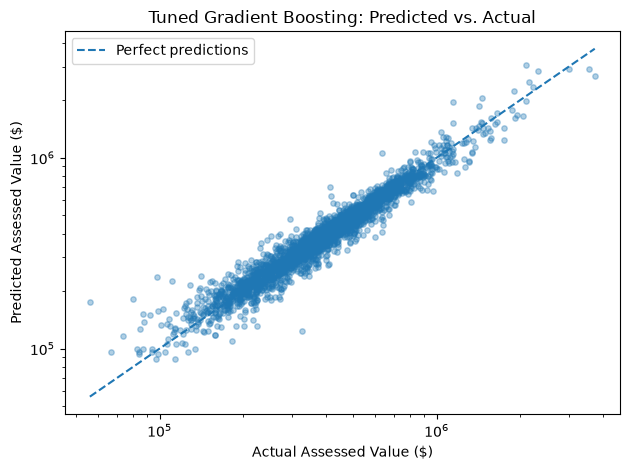

In [36]:
plot_sample = plot_data.sample(
    n=min(5000, len(plot_data)),
    random_state=42
)

plt.scatter(
    plot_sample["Actual"],
    plot_sample["Predicted"],
    alpha=0.35,
    s=15
)

lower = min(plot_sample["Actual"].min(), plot_sample["Predicted"].min())
upper = max(plot_sample["Actual"].max(), plot_sample["Predicted"].max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect predictions"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Actual Assessed Value ($)")
plt.ylabel("Predicted Assessed Value ($)")
plt.title("Tuned Gradient Boosting: Predicted vs. Actual")
plt.legend()
plt.tight_layout()
plt.show()

The predicted-vs-actual chart shows that the tuned gradient boosting model predicts house values fairly accurately across most of the price range. Most points are close to the line of perfect predictions.
The predictions vary more for houses valued below about $150,000, and the model underpredicts a few of the most expensive houses.

In [37]:
error_data = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": tuned_test_pred
})

error_data["Absolute Error"] = (
    error_data["Actual"] - error_data["Predicted"]
).abs()

error_data["Percentage Error"] = (
    error_data["Absolute Error"] / error_data["Actual"]
) * 100

bins = [0, 300000, 500000, 800000, 1500000, np.inf]

labels = [
    "Under 300K",
    "300K–500K",
    "500K–800K",
    "800K–1.5M",
    "Over 1.5M"
]

error_data["Band"] = pd.cut(
    error_data["Actual"],
    bins=bins,
    labels=labels,
    right=False
)

band_results = error_data.groupby(
    "Band",
    observed=False
).agg(
    MAE=("Absolute Error", "mean"),
    Median_Percentage_Error=("Percentage Error", "median"),
    Number_of_Houses=("Actual", "count")
)

band_results.round(2)

,MAE,Median_Percentage_Error,Number_of_Houses
Band,,,
Under 300K,23416.26,7.74,6801
300K–500K,18771.77,3.27,17889
500K–800K,26012.16,2.63,9524
800K–1.5M,102932.79,7.37,1190
Over 1.5M,325802.58,9.89,127


The model performs best on mid-priced houses. The 300K–500K and 500K–800K bands contain about 77% of the test houses, with median percentage errors of 3.3% and 2.6%.
Accuracy is lower at both ends of the price range.These results suggest that houses at the extremes are harder to predict. The dataset may lack details about the condition of cheaper houses, while expensive houses are less common in the training data. The app will show a prediction range and warn users that predictions may be less reliable for very large or expensive houses.